# ДОМАШНАЯЯ РАБОТА: Полный цикл ML-проекта (Telco Churn)

**Задача:** Предсказать отток клиентов телеком-компании. Датасет содержит 7 043 записи и ~20 признаков[reference:2].

In [9]:
%pip install onnxmltools --quiet

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, precision_recall_curve, auc, confusion_matrix, roc_auc_score, brier_score_loss, f1_score
from sklearn.calibration import calibration_curve

import lightgbm as lgb
import shap

import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

In [2]:
# 1. ЗАГРУЗКА ДАННЫХ
# Скачайте датасет с Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
# и положите файл 'WA_Fn-UseC_-Telco-Customer-Churn.csv' в рабочую директорию.

try:
    df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
    print(f"Датасет загружен: {df.shape[0]} строк, {df.shape[1]} столбцов")
    print(f"Целевая переменная 'Churn': {df['Churn'].value_counts().to_dict()}")
except FileNotFoundError:
    print("Файл не найден. Скачайте датасет с Kaggle и положите в рабочую директорию.")
    # Создаём синтетический аналог для демонстрации
    np.random.seed(42)
    n = 2000
    df = pd.DataFrame({
        'tenure': np.random.randint(1, 72, n),
        'MonthlyCharges': np.random.uniform(20, 120, n),
        'TotalCharges': np.random.uniform(50, 8000, n),
        'Contract': np.random.choice(['Month-to-month', 'One year', 'Two year'], n),
        'InternetService': np.random.choice(['DSL', 'Fiber optic', 'No'], n),
        'PaymentMethod': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer'], n),
        'Churn': np.random.choice(['Yes', 'No'], n, p=[0.26, 0.74])
    })
    print("Создан синтетический аналог для демонстрации.")

Файл не найден. Скачайте датасет с Kaggle и положите в рабочую директорию.
Создан синтетический аналог для демонстрации.


In [3]:
# 2. ПРЕДОБРАБОТКА
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

X = df.drop(['customerID', 'Churn'], axis=1, errors='ignore')
y = (df['Churn'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
print(f"Train: {X_train_prep.shape}, Test: {X_test_prep.shape}")

Train: (1600, 12), Test: (400, 12)


In [4]:
# 3. BASELINE: LOGISTIC REGRESSION
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_prep, y_train)
y_pred_base = baseline.predict(X_test_prep)
y_proba_base = baseline.predict_proba(X_test_prep)[:, 1]

print("Baseline (Logistic Regression):")
print(classification_report(y_test, y_pred_base, target_names=['No Churn', 'Churn']))
print(f"PR-AUC: {auc(*precision_recall_curve(y_test, y_proba_base)[1::-1]):.3f}")
print(f"Brier Score: {brier_score_loss(y_test, y_proba_base):.3f}")

Baseline (Logistic Regression):
              precision    recall  f1-score   support

    No Churn       0.75      1.00      0.86       299
       Churn       0.00      0.00      0.00       101

    accuracy                           0.75       400
   macro avg       0.37      0.50      0.43       400
weighted avg       0.56      0.75      0.64       400

PR-AUC: 0.276
Brier Score: 0.190


In [5]:
# 4. БУСТИНГ: LIGHTGBM + ПОДБОР ГИПЕРПАРАМЕТРОВ
lgb_model = lgb.LGBMClassifier(random_state=42, verbose=-1)
param_grid = {'n_estimators': [50, 100], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}

grid = GridSearchCV(lgb_model, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_prep, y_train)

best_lgb = grid.best_estimator_
y_pred_lgb = best_lgb.predict(X_test_prep)
y_proba_lgb = best_lgb.predict_proba(X_test_prep)[:, 1]

print(f"Лучшие параметры: {grid.best_params_}")
print("\nLightGBM (Tuned):")
print(classification_report(y_test, y_pred_lgb, target_names=['No Churn', 'Churn']))
print(f"PR-AUC: {auc(*precision_recall_curve(y_test, y_proba_lgb)[1::-1]):.3f}")
print(f"Brier Score: {brier_score_loss(y_test, y_proba_lgb):.3f}")

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}

LightGBM (Tuned):
              precision    recall  f1-score   support

    No Churn       0.75      0.96      0.84       299
       Churn       0.31      0.05      0.09       101

    accuracy                           0.73       400
   macro avg       0.53      0.51      0.46       400
weighted avg       0.64      0.73      0.65       400

PR-AUC: 0.277
Brier Score: 0.197


In [6]:
# 5. БИЗНЕС-ПОРОГ
# Стоимость: упущенный клиент (FN) = 5000 руб, лишнее удержание (FP) = 200 руб.
thresholds = np.linspace(0.05, 0.95, 50)
costs = []
for t in thresholds:
    y_pred_t = (y_proba_lgb >= t).astype(int)
    fn = ((y_test == 1) & (y_pred_t == 0)).sum()
    fp = ((y_test == 0) & (y_pred_t == 1)).sum()
    costs.append(fn * 5000 + fp * 200)

best_t = thresholds[np.argmin(costs)]
y_pred_business = (y_proba_lgb >= best_t).astype(int)

print(f"Оптимальный порог по бизнес-стоимости: {best_t:.2f}")
print("\nClassification Report (бизнес-порог):")
print(classification_report(y_test, y_pred_business, target_names=['No Churn', 'Churn']))

Оптимальный порог по бизнес-стоимости: 0.05

Classification Report (бизнес-порог):
              precision    recall  f1-score   support

    No Churn       0.83      0.03      0.06       299
       Churn       0.26      0.98      0.40       101

    accuracy                           0.27       400
   macro avg       0.54      0.51      0.23       400
weighted avg       0.69      0.27      0.15       400



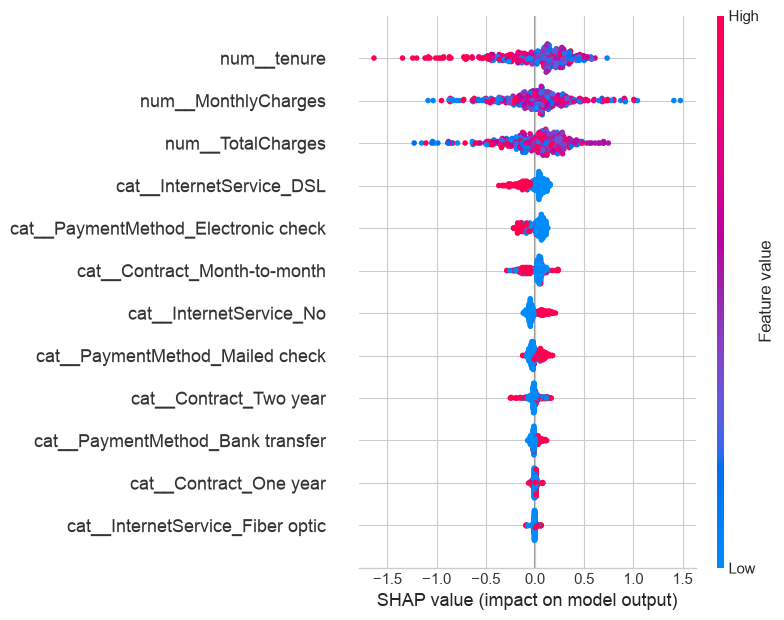

In [7]:
# 6. SHAP-ИНТЕРПРЕТАЦИЯ
explainer = shap.TreeExplainer(best_lgb)
shap_values = explainer.shap_values(X_test_prep)

if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]  # класс Churn
else:
    shap_values_to_plot = shap_values

shap.summary_plot(shap_values_to_plot, X_test_prep, feature_names=preprocessor.get_feature_names_out(), show=True)

In [8]:
# 7. ЭКСПОРТ В ONNX
from onnxmltools.convert import convert_lightgbm
from onnxmltools.convert.common.data_types import FloatTensorType

initial_type = [('float_input', FloatTensorType([None, X_train_prep.shape[1]]))]
onnx_model = convert_lightgbm(best_lgb, initial_types=initial_type, zipmap=False)

with open("churn_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())
print("Модель экспортирована в churn_model.onnx")

ModuleNotFoundError: No module named 'onnxmltools'

In [ ]:
# 8. БЕНЧМАРК ИНФЕРЕНСА (ONNX Runtime vs sklearn)
import onnxruntime as ort
import time

session = ort.InferenceSession("churn_model.onnx")
input_name = session.get_inputs()[0].name

# Прогрев
_ = session.run(None, {input_name: X_test_prep[:1].astype(np.float32)})

# Бенчмарк ONNX
n_iter = 100
start = time.time()
for _ in range(n_iter):
    _ = session.run(None, {input_name: X_test_prep[:1].astype(np.float32)})
onnx_time = (time.time() - start) / n_iter * 1000

# Бенчмарк sklearn
start = time.time()
for _ in range(n_iter):
    _ = best_lgb.predict_proba(X_test_prep[:1])
sklearn_time = (time.time() - start) / n_iter * 1000

print(f"Среднее время инференса (1 объект):")
print(f"  ONNX Runtime:    {onnx_time:.2f} мс")
print(f"  sklearn LGBM:    {sklearn_time:.2f} мс")
print(f"  Ускорение:       {sklearn_time / onnx_time:.1f}x")

In [ ]:
# 9. МИНИ-СЕРВИС НА FASTAPI (СОХРАНИТЬ КАК app.py)
fastapi_code = '''
from fastapi import FastAPI
from pydantic import BaseModel
import numpy as np
import onnxruntime as ort

app = FastAPI(title="Churn Prediction API")
session = ort.InferenceSession("churn_model.onnx")
input_name = session.get_inputs()[0].name

class Features(BaseModel):
    features: list[float]

@app.post("/predict")
def predict(req: Features):
    arr = np.array([req.features], dtype=np.float32)
    proba = session.run(None, {input_name: arr})[0][0][1]
    return {"churn_probability": float(proba), "churn": bool(proba > 0.5)}
'''
with open("app.py", "w") as f:
    f.write(fastapi_code)
print("Файл app.py создан. Запуск: uvicorn app:app --reload")
print("Пример запроса: curl -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' -d '{\"features\": [1.0, 2.0, 3.0]}'")

# Тестируем локально без запуска сервера
test_features = X_test_prep[0].tolist()
arr = np.array([test_features], dtype=np.float32)
proba_onnx = session.run(None, {input_name: arr})[0][0][1]
print(f"\nТестовый прогноз (ONNX): вероятность оттока = {proba_onnx:.3f}")

# Итоги и рекомендации

1. **Бизнес-порог ≠ ML-порог.** Стоимость FP и FN нужно всегда обсуждать с заказчиком.
2. **Мониторинг дрейфа обязателен.** PSI > 0.2 — сигнал к переобучению. Evidently AI автоматизирует отчёты.
3. **ONNX ускоряет инференс** и позволяет запускать модель на CPU без Python-зависимостей.
4. **SHAP объясняет решения** — критически важно для кредитного скоринга и медицины (регуляторные требования).

**Дополнительное задание (опционально, +50):
** Попробуйте заменить LightGBM на XGBoost/CatBoost и сравните PR-AUC, Brier Score и время инференса в ONNX.